<a href="https://colab.research.google.com/github/hersil7/cdd_ucsc/blob/main/S5_Notebook_Laboratorio_CDD_Final_liviano.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto analítico · ENE 2025 · cuaderno reproducible

**Objetivo.** Cuantificar cómo varía la desocupación entre regiones agrupadas, grupos de edad y sexo dentro del nivel medio, usando la base anual de la Encuesta Nacional de Empleo 2025 y su panel de cuatro visitas.

**Flujo.** Carga del archivo crudo del INE → panel de personas con cuatro visitas → limpieza de centinelas → variables derivadas → tasas ponderadas → robustez por particiones de personas → detección de anomalías → salidas sin identificadores.

**Cómo ejecutar.** Ver `README.md`. El archivo `ano-2025.csv` se descarga desde el INE.

**Semilla:** 42 · **Bibliotecas:** ver `requirements.txt`.

## 1 · Configuración

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42
np.random.seed(SEMILLA)

# RUTA_DATOS = 'data/ano-2025.csv'      # archivo oficial del INE, ver README
RUTA_DATOS = '/content/drive/Othercomputers/Notebook HP/Ing Informática UCSC/Trimestre 3/1 Ciencia de datos/Evaluaciones/Semana 1/Lab 1/ano-2025.csv' # en colab

CARPETA_SALIDA = 'salidas'            # solo agregados, sin identificadores
os.makedirs(CARPETA_SALIDA, exist_ok=True)

# Columnas necesarias. Se excluyen comuna, ocupación, cargo y demás campos no usados (minimización)
COLUMNAS = ['idrph', 'mes_central', 'activ', 'fact_anual', 'edad', 'sexo', 'region', 'nivel', 'habituales']

# Códigos centinela por columna, según el catálogo
CENTINELAS = {'nivel': [88, 99], 'habituales': [888, 999]}

Se fija la semilla y se declaran las columnas. Los centinelas se definen por columna, no con una lista global, según la bitácora de decisiones.

## 2 · Carga del archivo crudo

In [ ]:
raw = pd.read_csv(RUTA_DATOS, sep=';', encoding='utf-8', dtype=str,
                  usecols=COLUMNAS, low_memory=False)
print('Registros de la base anual:', len(raw), '| personas distintas:', raw['idrph'].nunique())
assert len(raw) == 390903, 'La base no coincide con la versión 2025 del INE'

Registros de la base anual: 390903 | personas distintas: 177402


La base anual tiene 390.903 registros. Se verifica el tamaño antes de seguir, para detectar un archivo distinto.

## 3 · Panel de personas con cuatro visitas

In [ ]:
n_visitas = raw.groupby('idrph')['idrph'].transform('size')
df = raw[n_visitas == 4].copy()
print('Panel:', len(df), 'registros |', df['idrph'].nunique(), 'personas')
assert len(df) == 118760 and df['idrph'].nunique() == 29690

Panel: 118760 registros | 29690 personas


Se conservan las personas que aparecen exactamente cuatro veces. Esto da una población fija de cuatro trimestres, con 29.690 personas y 118.760 registros.

## 4 · Limpieza: tipos y centinelas

In [ ]:
def a_numero(s):
    """Convierte a número aceptando coma decimal. Lo que no se pueda convertir queda vacío."""
    return pd.to_numeric(s.astype(str).str.replace(',', '.', regex=False), errors='coerce')

for col in ['activ', 'fact_anual', 'edad', 'sexo', 'region', 'nivel', 'habituales']:
    df[col] = a_numero(df[col])

for col, codigos in CENTINELAS.items():
    df[col] = df[col].mask(df[col].isin(codigos))

print('Vacíos por columna:', df[COLUMNAS[1:]].isna().sum().to_dict())

Vacíos por columna: {'mes_central': 0, 'activ': 18321, 'fact_anual': 0, 'edad': 0, 'sexo': 0, 'region': 0, 'nivel': 4, 'habituales': 68740}


Se convierte la coma decimal antes de la conversión a número, y los códigos 88, 99, 888 y 999 pasan a vacío solo en las columnas donde el catálogo los define. `meses_ocup_actual` no se carga, porque tiene un error de conversión documentado en la bitácora.

## 5 · Variables derivadas

In [ ]:
MAPA_REGION = {13: 'Metropolitana', 5: 'Valparaíso', 8: 'Biobío y Ñuble', 16: 'Biobío y Ñuble',
              6: 'Centro', 7: 'Centro', 1: 'Extremo norte', 15: 'Extremo norte',
              2: 'Norte', 3: 'Norte', 4: 'Norte', 9: 'Sur', 10: 'Sur', 14: 'Sur',
              11: 'Extremo sur', 12: 'Extremo sur'}

df['region_grupo'] = df['region'].map(MAPA_REGION)
df['nivel_grupo'] = pd.Series(np.select(
    [df['nivel'].between(0, 3), df['nivel'].between(4, 6) | (df['nivel'] == 14), df['nivel'].between(7, 13)],
    ['Básica o menos', 'Media', 'Superior'], default=None), index=df.index)
df['tramo_edad'] = pd.cut(df['edad'], [14, 24, 34, 44, 54, 64, 120],
                          labels=['15-24', '25-34', '35-44', '45-54', '55-64', '65+'])
df['sexo'] = df['sexo'].map({1: 'Hombre', 2: 'Mujer'})
print(df[['region_grupo', 'nivel_grupo', 'tramo_edad', 'sexo']].isna().sum().to_dict())

{'region_grupo': 0, 'nivel_grupo': 4, 'tramo_edad': 18321, 'sexo': 0}


La región se generaliza en ocho grupos y la edad en tramos de diez años, así que el archivo de análisis no conserva comuna ni edad exacta. El nivel se agrupa en tres categorías; el código 14 (normalista) se asigna a media, según la bitácora.

## 6 · Fuerza de trabajo

In [ ]:
ft = df[df['activ'].isin([1, 2]) & df['fact_anual'].notna()].copy()
ft['desocupado'] = ft['activ'].eq(2)
print('Fuerza de trabajo:', len(ft), '| desocupados:', int(ft['desocupado'].sum()))
assert len(ft) == 54489 and int(ft['desocupado'].sum()) == 4383

Fuerza de trabajo: 54489 | desocupados: 4383


La población de referencia son las visitas con condición ocupada o desocupada. Los inactivos y los menores de 15 años quedan fuera de este análisis.

## 7 · Tasas ponderadas y hallazgos

In [ ]:
def tasa(x):
    """Tasa de desocupación ponderada por fact_anual, en porcentaje."""
    return x.loc[x['desocupado'], 'fact_anual'].sum() / x['fact_anual'].sum() * 100

t_region = ft.groupby('region_grupo', observed=True).apply(tasa).sort_values()
t_tramo = ft.groupby('tramo_edad', observed=True).apply(tasa).sort_index()
n_des = ft.groupby('region_grupo', observed=True)['desocupado'].sum()

razon_region = t_region['Extremo norte'] / t_region['Extremo sur']
t_sin_15 = t_tramo.drop('15-24')
razon_edad = t_sin_15['25-34'] / t_sin_15['65+']

m_media = ft[ft['nivel_grupo'] == 'Media']
brecha_media = tasa(m_media[m_media['sexo'] == 'Mujer']) - tasa(m_media[m_media['sexo'] == 'Hombre'])

print(f'Hallazgo 1 · Extremo norte / Extremo sur = {razon_region:.2f}')
print(f'Hallazgo 2 · 25-34 / 65+ (desde 25 años) = {razon_edad:.2f}')
print(f'Hallazgo 3 · Brecha M-H en nivel medio  = {brecha_media:.2f} puntos')
print('Tasa 15-24 (reportada aparte):', round(t_tramo['15-24'], 2))

Hallazgo 1 · Extremo norte / Extremo sur = 2.42
Hallazgo 2 · 25-34 / 65+ (desde 25 años) = 2.20
Hallazgo 3 · Brecha M-H en nivel medio  = 3.09 puntos
Tasa 15-24 (reportada aparte): 25.36


/tmp/ipykernel_957/101121531.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t_region = ft.groupby('region_grupo', observed=True).apply(tasa).sort_values()
/tmp/ipykernel_957/101121531.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t_tramo = ft.groupby('tramo_edad', observed=True).apply(tasa).sort_index()


Los tres hallazgos se calculan con la misma función de tasa. El tramo de 15 a 24 años se reporta aparte, porque su tasa está influida por quienes estudian.

## 8 · Figuras explicativas

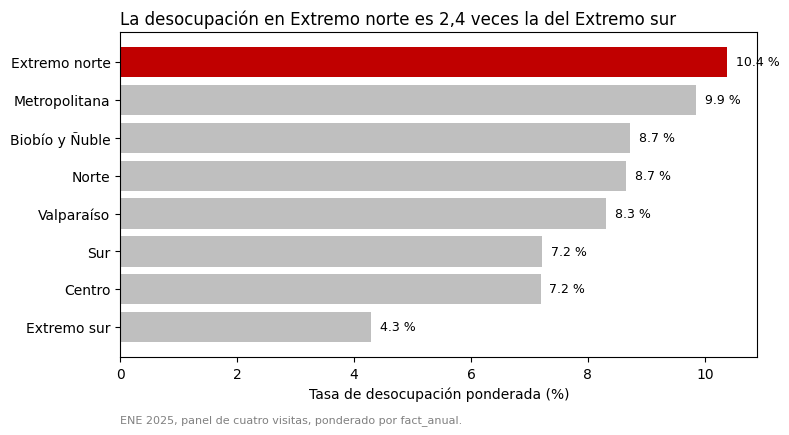

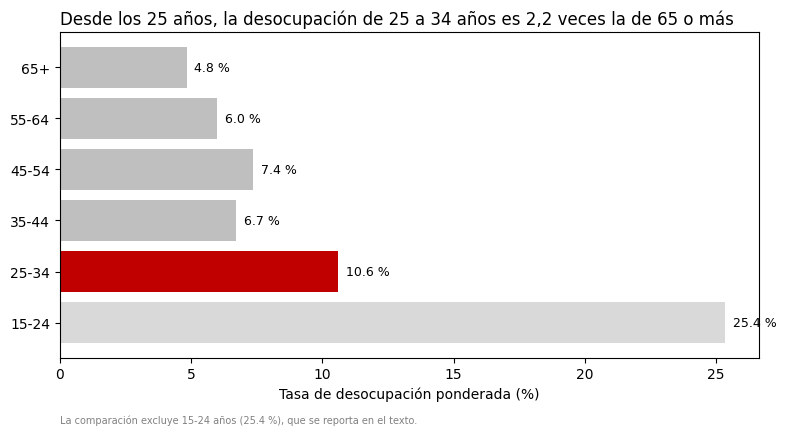

In [ ]:
# Figura 1: región
colores = ['#BFBFBF'] * len(t_region)
colores[list(t_region.index).index('Extremo norte')] = '#C00000'
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(t_region.index.astype(str), t_region.values, color=colores)
for i, v in enumerate(t_region.values):
    ax.text(v + 0.15, i, f'{v:.1f} %', va='center', fontsize=9)
ax.set_title(f'La desocupación en Extremo norte es {razon_region:.1f} veces la del Extremo sur'.replace('.', ','),
             loc='left', fontsize=12)
ax.set_xlabel('Tasa de desocupación ponderada (%)')
ax.text(0, -0.2, 'ENE 2025, panel de cuatro visitas, ponderado por fact_anual.',
        transform=ax.transAxes, fontsize=8, color='gray')
plt.tight_layout(); plt.savefig(f'{CARPETA_SALIDA}/figura_1.png', dpi=200, bbox_inches='tight'); plt.show()

# Figura 2: tramo de edad, comparación desde 25 años
colores = ['#D9D9D9' if t == '15-24' else '#BFBFBF' for t in t_tramo.index]
colores[list(t_tramo.index).index('25-34')] = '#C00000'
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(t_tramo.index.astype(str), t_tramo.values, color=colores)
for i, v in enumerate(t_tramo.values):
    ax.text(v + 0.3, i, f'{v:.1f} %', va='center', fontsize=9)
ax.set_title(f'Desde los 25 años, la desocupación de 25 a 34 años es {razon_edad:.1f} veces la de 65 o más'.replace('.', ','),
             loc='left', fontsize=12)
ax.set_xlabel('Tasa de desocupación ponderada (%)')
ax.text(0, -0.2, f'La comparación excluye 15-24 años ({t_tramo["15-24"]:.1f} %), que se reporta en el texto.',
        transform=ax.transAxes, fontsize=7, color='gray')
plt.tight_layout(); plt.savefig(f'{CARPETA_SALIDA}/figura_2.png', dpi=200, bbox_inches='tight'); plt.show()

Figura 1: región, con el titular calculado en el código. Figura 2: tramo de edad, desde los 25 años. En ambas, el titular proviene de las mismas cifras que se imprimen arriba.

## 9 · Robustez: 30 particiones por persona

In [ ]:
ids = ft['idrph'].unique()
R_region, R_edad, B_media = [], [], []
for r in range(30):
    rng = np.random.default_rng(r)   # particiones 0 a 29, mismas que en el informe
    mitad = set(ids[rng.random(len(ids)) < 0.5])
    for sub in [ft[ft['idrph'].isin(mitad)], ft[~ft['idrph'].isin(mitad)]]:
        tr = sub.groupby('region_grupo', observed=True).apply(tasa)
        R_region.append(tr['Extremo norte'] / tr['Extremo sur'])
        te = sub.groupby('tramo_edad', observed=True).apply(tasa)
        R_edad.append(te['25-34'] / te['65+'])
        ms = sub[sub['nivel_grupo'] == 'Media']
        B_media.append(tasa(ms[ms['sexo'] == 'Mujer']) - tasa(ms[ms['sexo'] == 'Hombre']))

resumen_robustez = pd.DataFrame({
    'hallazgo': ['Región: Extremo norte / Extremo sur', 'Edad: 25-34 / 65+', 'Brecha M-H en nivel medio (puntos)'],
    'completa': [razon_region, razon_edad, brecha_media],
    'media_60_mitades': [np.mean(R_region), np.mean(R_edad), np.mean(B_media)],
    'desviacion_60_mitades': [np.std(R_region), np.std(R_edad), np.std(B_media)],
}).round(2)
print(resumen_robustez.to_string(index=False))
print('Mitades con razón regional > 1:', sum(r > 1 for r in R_region), 'de 60')
print('Mitades con razón por edad > 1:', sum(r > 1 for r in R_edad), 'de 60')

/tmp/ipykernel_957/30936332.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tr = sub.groupby('region_grupo', observed=True).apply(tasa)
/tmp/ipykernel_957/30936332.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  te = sub.groupby('tramo_edad', observed=True).apply(tasa)
/tmp/ipykernel_957/30936332.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is depr

                           hallazgo  completa  media_60_mitades  desviacion_60_mitades
Región: Extremo norte / Extremo sur      2.42              2.47                   0.45
                  Edad: 25-34 / 65+      2.20              2.22                   0.29
 Brecha M-H en nivel medio (puntos)      3.09              3.09                   0.70
Mitades con razón regional > 1: 60 de 60
Mitades con razón por edad > 1: 60 de 60


/tmp/ipykernel_957/30936332.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tr = sub.groupby('region_grupo', observed=True).apply(tasa)
/tmp/ipykernel_957/30936332.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  te = sub.groupby('tramo_edad', observed=True).apply(tasa)
/tmp/ipykernel_957/30936332.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is depr

Cada hallazgo se repite en 60 mitades independientes de personas (particiones 0 a 29, dos mitades cada una). La media y la desviación describen la estabilidad interna del cálculo, no un intervalo de confianza con diseño muestral complejo. La desviación depende de la partición: con otra semilla base, la desviación de la razón regional cambia de 0,45 a 0,20; esto se declara como limitación. Los identificadores se usan solo en memoria para formar las mitades.

## 10 · Detección de anomalías (minería)

In [ ]:
# Unidad: persona ocupada, con el promedio de sus visitas ocupadas
oc = ft[ft['activ'] == 1]
per = (oc.groupby('idrph')
         .agg(edad=('edad', 'mean'), habituales=('habituales', 'mean'),
              nivel=('nivel', 'mean'), n_visitas=('edad', 'size'))
         .dropna(subset=['edad', 'habituales', 'nivel']))
per['nivel_r'] = per['nivel'].rank(pct=True)

X = per[['edad', 'habituales', 'nivel_r']]
Z = (X - X.mean()) / X.std()
per['distancia'] = np.linalg.norm(Z.values - Z.values.mean(axis=0), axis=1)

UMBRAL = per['distancia'].quantile(0.999)
n_marcados = int((per['distancia'] > UMBRAL).sum())
print(f'Personas ocupadas: {len(per)} | umbral p99,9 = {UMBRAL:.3f} | casos a revisar: {n_marcados}')
print('Horas habituales > 100 entre los marcados:', int((per.loc[per['distancia'] > UMBRAL, 'habituales'] > 100).sum()))

Personas ocupadas: 15363 | umbral p99,9 = 4.023 | casos a revisar: 16
Horas habituales > 100 entre los marcados: 3


El umbral del percentil 99,9 se elige para revisar entre 10 y 20 casos. Los casos marcados se caracterizan en la entrega 3, con sus visitas originales. Aquí solo se imprime el conteo, sin identificadores.

## 11 · Tratamiento de datos personales y salidas

In [ ]:
salidas = {
    'tasa_region.csv': pd.DataFrame({'region_grupo': t_region.index, 'tasa_pct': t_region.values.round(2),
                                     'desocupados_sin_ponderar': n_des.reindex(t_region.index).values}),
    'tasa_tramo.csv': pd.DataFrame({'tramo_edad': t_tramo.index.astype(str), 'tasa_pct': t_tramo.values.round(2)}),
    'robustez.csv': resumen_robustez,
}
for nombre, tabla in salidas.items():
    assert 'idrph' not in tabla.columns
    tabla.to_csv(f'{CARPETA_SALIDA}/{nombre}', index=False, encoding='utf-8')

print(sorted(os.listdir(CARPETA_SALIDA)))

['figura_1.png', 'figura_2.png', 'robustez.csv', 'tasa_region.csv', 'tasa_tramo.csv']


**Tratamiento aplicado.** El identificador `idrph` y las variables de visita solo se usan en memoria. No se publican en ninguna salida. La edad se generaliza en tramos de diez años y la región en ocho grupos. Se suprimen comuna, ocupación, cargo y el resto de campos no usados. El dato que no se conserva es la posibilidad de seguir a una misma persona entre visitas en el archivo publicado, y la edad y comuna exactas. El archivo de datos no se incluye en el repositorio: se obtiene desde el INE.

**Enlace a mi repositorio:** [https://github.com/hersil7/cdd_ucsc](https://github.com/hersil7/cdd_ucsc)